In [127]:
import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [128]:
df = pd.read_csv("../dataset.csv")
df

,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,1,1,...,1,80,0,8,0,1,6,4,0,5
1,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,1,2,...,4,80,1,10,3,3,10,7,1,7
2,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,1,4,...,2,80,0,7,3,3,0,0,0,0
3,33,No,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,1,5,...,3,80,0,8,3,3,8,7,3,0
4,27,No,Travel_Rarely,591,Research & Development,2,1,Medical,1,7,...,4,80,1,6,3,3,2,2,2,2
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1465,36,No,Travel_Frequently,884,Research & Development,23,2,Medical,1,2061,...,3,80,1,17,3,3,5,2,0,3
1466,39,No,Travel_Rarely,613,Research & Development,6,1,Medical,1,2062,...,1,80,1,9,5,3,7,7,1,7
1467,27,No,Travel_Rarely,155,Research & Development,4,3,Life Sciences,1,2064,...,2,80,1,6,0,3,6,2,0,3
1468,49,No,Travel_Frequently,1023,Sales,2,3,Medical,1,2065,...,4,80,0,17,3,2,9,6,0,8


In [129]:
# basic analysis
df.shape

(1470, 35)

In [130]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1470 entries, 0 to 1469
Data columns (total 35 columns):
 #   Column                    Non-Null Count  Dtype
---  ------                    --------------  -----
 0   Age                       1470 non-null   int64
 1   Attrition                 1470 non-null   str  
 2   BusinessTravel            1470 non-null   str  
 3   DailyRate                 1470 non-null   int64
 4   Department                1470 non-null   str  
 5   DistanceFromHome          1470 non-null   int64
 6   Education                 1470 non-null   int64
 7   EducationField            1470 non-null   str  
 8   EmployeeCount             1470 non-null   int64
 9   EmployeeNumber            1470 non-null   int64
 10  EnvironmentSatisfaction   1470 non-null   int64
 11  Gender                    1470 non-null   str  
 12  HourlyRate                1470 non-null   int64
 13  JobInvolvement            1470 non-null   int64
 14  JobLevel                  1470 non-null   int64
 15

In [131]:
df.duplicated().sum() # no missing or duplicated columns 

np.int64(0)

In [132]:
# column wise analysis
df["BusinessTravel"].value_counts()

BusinessTravel
Travel_Rarely        1043
Travel_Frequently     277
Non-Travel            150
Name: count, dtype: int64

In [133]:
df["Department"].value_counts()

Department
Research & Development    961
Sales                     446
Human Resources            63
Name: count, dtype: int64

In [134]:
df["DailyRate"].describe()

count    1470.000000
mean      802.485714
std       403.509100
min       102.000000
25%       465.000000
50%       802.000000
75%      1157.000000
max      1499.000000
Name: DailyRate, dtype: float64

In [135]:
df["Age"].describe()

count    1470.000000
mean       36.923810
std         9.135373
min        18.000000
25%        30.000000
50%        36.000000
75%        43.000000
max        60.000000
Name: Age, dtype: float64

In [136]:
df["DistanceFromHome"].describe()

count    1470.000000
mean        9.192517
std         8.106864
min         1.000000
25%         2.000000
50%         7.000000
75%        14.000000
max        29.000000
Name: DistanceFromHome, dtype: float64

In [137]:
df["EducationField"].value_counts()

EducationField
Life Sciences       606
Medical             464
Marketing           159
Technical Degree    132
Other                82
Human Resources      27
Name: count, dtype: int64

In [138]:
education = ["Below College", "College", "Bachelor", "Master", "Doctor"]
df["Education"] = df["Education"].astype(str)
for i in range(1, 6):
    idx = df[df["Education"] == str(i)].index
    df.loc[idx, "Education"] = education[i - 1]
df["Education"].value_counts()

Education
Bachelor         572
Master           398
College          282
Below College    170
Doctor            48
Name: count, dtype: int64

In [139]:
df = df.drop(["EmployeeCount", "EmployeeNumber", "StandardHours", "Over18"], axis = 1)

In [140]:
df

,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EnvironmentSatisfaction,Gender,...,PerformanceRating,RelationshipSatisfaction,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,41,Yes,Travel_Rarely,1102,Sales,1,College,Life Sciences,2,Female,...,3,1,0,8,0,1,6,4,0,5
1,49,No,Travel_Frequently,279,Research & Development,8,Below College,Life Sciences,3,Male,...,4,4,1,10,3,3,10,7,1,7
2,37,Yes,Travel_Rarely,1373,Research & Development,2,College,Other,4,Male,...,3,2,0,7,3,3,0,0,0,0
3,33,No,Travel_Frequently,1392,Research & Development,3,Master,Life Sciences,4,Female,...,3,3,0,8,3,3,8,7,3,0
4,27,No,Travel_Rarely,591,Research & Development,2,Below College,Medical,1,Male,...,3,4,1,6,3,3,2,2,2,2
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1465,36,No,Travel_Frequently,884,Research & Development,23,College,Medical,3,Male,...,3,3,1,17,3,3,5,2,0,3
1466,39,No,Travel_Rarely,613,Research & Development,6,Below College,Medical,4,Male,...,3,1,1,9,5,3,7,7,1,7
1467,27,No,Travel_Rarely,155,Research & Development,4,Bachelor,Life Sciences,2,Male,...,4,2,1,6,0,3,6,2,0,3
1468,49,No,Travel_Frequently,1023,Sales,2,Bachelor,Medical,4,Male,...,3,4,0,17,3,2,9,6,0,8


In [141]:
env_sat = ["low", "medium", "high", "very high"]
df["EnvironmentSatisfaction"] = df["EnvironmentSatisfaction"].astype(str)
df["JobInvolvement"] = df["JobInvolvement"].astype(str)
df["RelationshipSatisfaction"] = df["RelationshipSatisfaction"].astype(str)
for i in range(1, len(env_sat) + 1):
    idx = df[df["EnvironmentSatisfaction"] == str(i)].index
    df.loc[idx, "EnvironmentSatisfaction"] = env_sat[i - 1]
    idx1 = df[df["JobInvolvement"] == str(i)].index
    df.loc[idx1, "JobInvolvement"] = env_sat[i - 1]
    idx2 = df[df["RelationshipSatisfaction"] == str(i)].index
    df.loc[idx2, "RelationshipSatisfaction"] = env_sat[i - 1]

df["EnvironmentSatisfaction"].value_counts(), df["JobInvolvement"].value_counts(), df["RelationshipSatisfaction"].value_counts()

(EnvironmentSatisfaction
 high         453
 very high    446
 medium       287
 low          284
 Name: count, dtype: int64,
 JobInvolvement
 high         868
 medium       375
 very high    144
 low           83
 Name: count, dtype: int64,
 RelationshipSatisfaction
 high         459
 very high    432
 medium       303
 low          276
 Name: count, dtype: int64)

In [142]:
df["Gender"].value_counts()

Gender
Male      882
Female    588
Name: count, dtype: int64

In [143]:
df["HourlyRate"].describe()

count    1470.000000
mean       65.891156
std        20.329428
min        30.000000
25%        48.000000
50%        66.000000
75%        83.750000
max       100.000000
Name: HourlyRate, dtype: float64

In [144]:
df["JobLevel"].value_counts()

JobLevel
1    543
2    534
3    218
4    106
5     69
Name: count, dtype: int64

In [145]:
df["JobRole"].value_counts()

JobRole
Sales Executive              326
Research Scientist           292
Laboratory Technician        259
Manufacturing Director       145
Healthcare Representative    131
Manager                      102
Sales Representative          83
Research Director             80
Human Resources               52
Name: count, dtype: int64

In [146]:
df["MaritalStatus"].value_counts()

MaritalStatus
Married     673
Single      470
Divorced    327
Name: count, dtype: int64

In [147]:
df["MonthlyIncome"].describe(), df["MonthlyRate"].describe()

(count     1470.000000
 mean      6502.931293
 std       4707.956783
 min       1009.000000
 25%       2911.000000
 50%       4919.000000
 75%       8379.000000
 max      19999.000000
 Name: MonthlyIncome, dtype: float64,
 count     1470.000000
 mean     14313.103401
 std       7117.786044
 min       2094.000000
 25%       8047.000000
 50%      14235.500000
 75%      20461.500000
 max      26999.000000
 Name: MonthlyRate, dtype: float64)

In [148]:
df["OverTime"].value_counts()

OverTime
No     1054
Yes     416
Name: count, dtype: int64

In [149]:
df["PercentSalaryHike"].describe()

count    1470.000000
mean       15.209524
std         3.659938
min        11.000000
25%        12.000000
50%        14.000000
75%        18.000000
max        25.000000
Name: PercentSalaryHike, dtype: float64

In [150]:
per_rating = ["low", "good", "excellent", "outstanding"]
df["PerformanceRating"] = df["PerformanceRating"].astype(str)

for i in range(1, len(per_rating) + 1):
    idx = df[df["PerformanceRating"] == str(i)].index
    df.loc[idx, "PerformanceRating"] = per_rating[i - 1]

df["PerformanceRating"].value_counts()


PerformanceRating
excellent      1244
outstanding     226
Name: count, dtype: int64

In [151]:
wlb = ["bad", "good", "better", "best"]
df["WorkLifeBalance"] = df["WorkLifeBalance"].astype(str)

for i in range(1 , len(wlb) + 1):
    idx = df[df["WorkLifeBalance"] == str(i)].index
    df.loc[idx, "WorkLifeBalance"] = wlb[i - 1]

df["WorkLifeBalance"].value_counts()

WorkLifeBalance
better    893
good      344
best      153
bad        80
Name: count, dtype: int64

In [152]:
df["TotalWorkingYears"].describe()

count    1470.000000
mean       11.279592
std         7.780782
min         0.000000
25%         6.000000
50%        10.000000
75%        15.000000
max        40.000000
Name: TotalWorkingYears, dtype: float64

In [153]:
df["TrainingTimesLastYear"].value_counts()

TrainingTimesLastYear
2    547
3    491
4    123
5    119
1     71
6     65
0     54
Name: count, dtype: int64

In [154]:
df["YearsAtCompany"].describe()

count    1470.000000
mean        7.008163
std         6.126525
min         0.000000
25%         3.000000
50%         5.000000
75%         9.000000
max        40.000000
Name: YearsAtCompany, dtype: float64

In [155]:
df["YearsInCurrentRole"].describe()

count    1470.000000
mean        4.229252
std         3.623137
min         0.000000
25%         2.000000
50%         3.000000
75%         7.000000
max        18.000000
Name: YearsInCurrentRole, dtype: float64

In [156]:
df["YearsSinceLastPromotion"].describe()

count    1470.000000
mean        2.187755
std         3.222430
min         0.000000
25%         0.000000
50%         1.000000
75%         3.000000
max        15.000000
Name: YearsSinceLastPromotion, dtype: float64

In [157]:
df["YearsWithCurrManager"].describe()

count    1470.000000
mean        4.123129
std         3.568136
min         0.000000
25%         2.000000
50%         3.000000
75%         7.000000
max        17.000000
Name: YearsWithCurrManager, dtype: float64

In [158]:
df["Attrition"].value_counts()/len(df) * 100 # imbalanced dataset - use imblearn

Attrition
No     83.877551
Yes    16.122449
Name: count, dtype: float64

In [159]:
df["NumCompaniesWorked"].describe()

count    1470.000000
mean        2.693197
std         2.498009
min         0.000000
25%         1.000000
50%         2.000000
75%         4.000000
max         9.000000
Name: NumCompaniesWorked, dtype: float64

In [160]:
df.head()

,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EnvironmentSatisfaction,Gender,...,PerformanceRating,RelationshipSatisfaction,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,41,Yes,Travel_Rarely,1102,Sales,1,College,Life Sciences,medium,Female,...,excellent,low,0,8,0,bad,6,4,0,5
1,49,No,Travel_Frequently,279,Research & Development,8,Below College,Life Sciences,high,Male,...,outstanding,very high,1,10,3,better,10,7,1,7
2,37,Yes,Travel_Rarely,1373,Research & Development,2,College,Other,very high,Male,...,excellent,medium,0,7,3,better,0,0,0,0
3,33,No,Travel_Frequently,1392,Research & Development,3,Master,Life Sciences,very high,Female,...,excellent,high,0,8,3,better,8,7,3,0
4,27,No,Travel_Rarely,591,Research & Development,2,Below College,Medical,low,Male,...,excellent,very high,1,6,3,better,2,2,2,2


<Axes: xlabel='BusinessTravel', ylabel='count'>

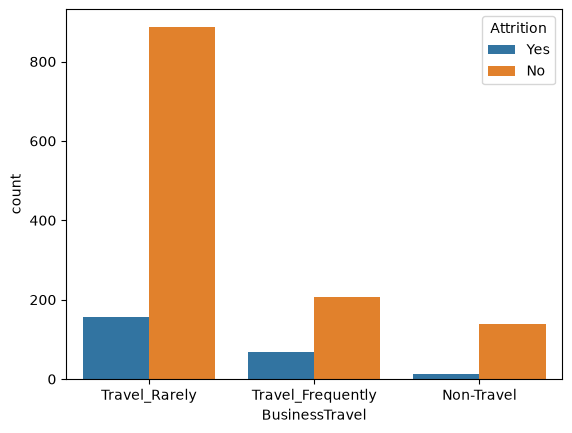

In [161]:
sns.countplot(df, x = "BusinessTravel", hue = "Attrition") # people traveling rarely have more attrition rates 

<Axes: xlabel='Department', ylabel='count'>

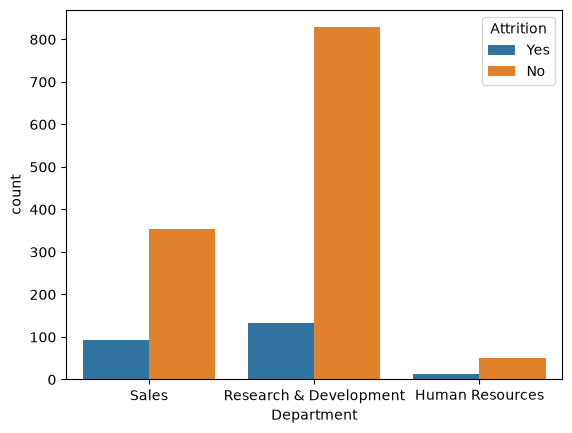

In [162]:
sns.countplot(df, x = "Department", hue = "Attrition") # higher attrition in R and D 

<Axes: xlabel='Education', ylabel='count'>

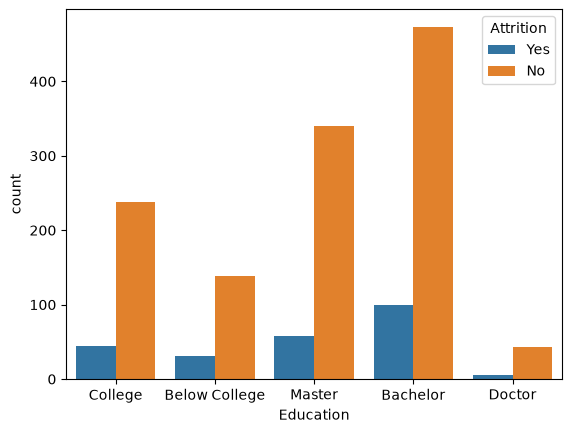

In [163]:
sns.countplot(df, x = "Education", hue = "Attrition") # most of the attrition happens at bachelor and masters degree holders 

<Axes: xlabel='count', ylabel='EducationField'>

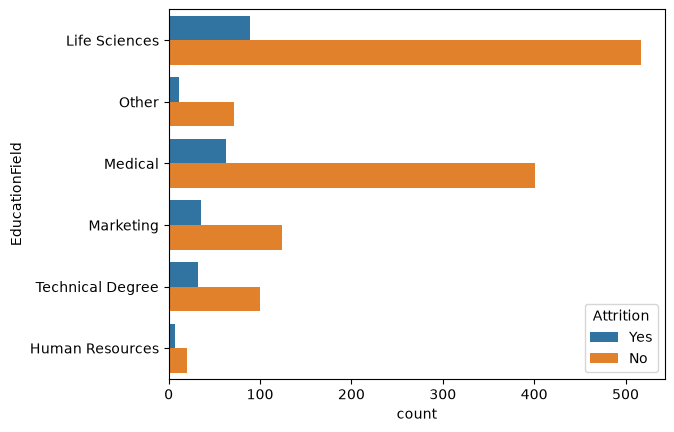

In [164]:
sns.countplot(df, y = "EducationField", hue = "Attrition") # highest attrition rates in life Sciences and medical

<Axes: xlabel='EnvironmentSatisfaction', ylabel='count'>

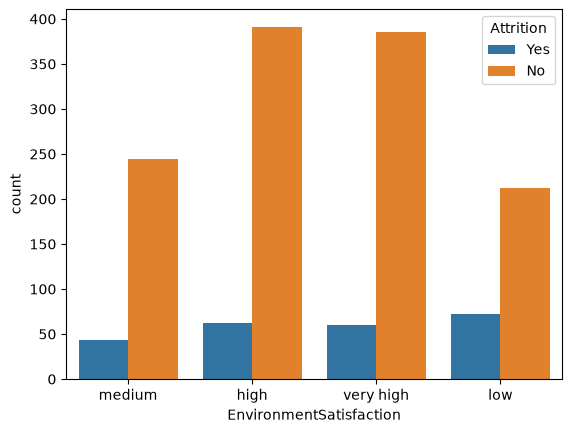

In [165]:
sns.countplot(df, x = "EnvironmentSatisfaction", hue = "Attrition") # more people with higher env satisfaction levels have left the org

<Axes: xlabel='Gender', ylabel='count'>

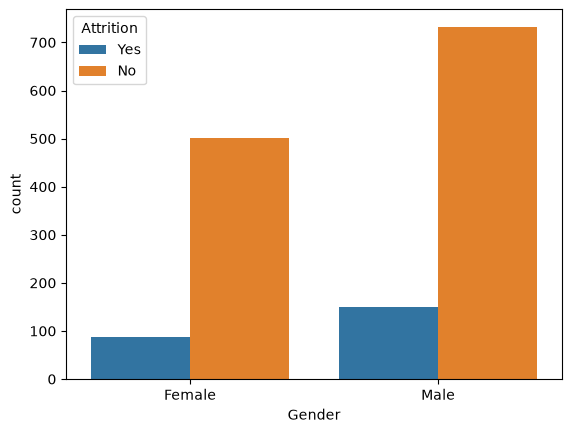

In [166]:
sns.countplot(df, x = "Gender", hue = "Attrition")

<Axes: xlabel='PerformanceRating', ylabel='count'>

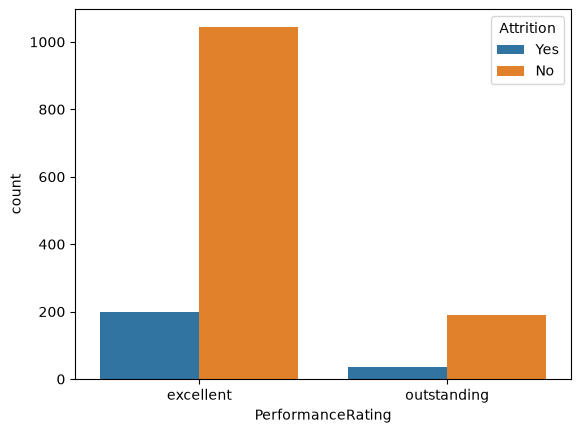

In [167]:
sns.countplot(df, x = "PerformanceRating", hue = "Attrition") # most of the comparitively poorer performers have left the company

<Axes: xlabel='Age', ylabel='Density'>

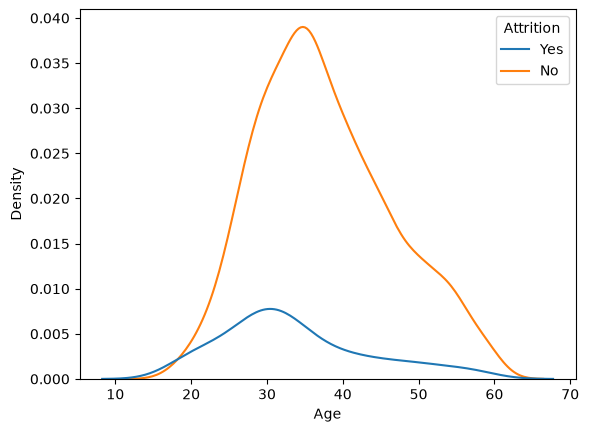

In [168]:
sns.kdeplot(df, x = "Age", hue = "Attrition") # most of the attrition happening with people of around 25-40 years of age

<Axes: xlabel='DailyRate', ylabel='Density'>

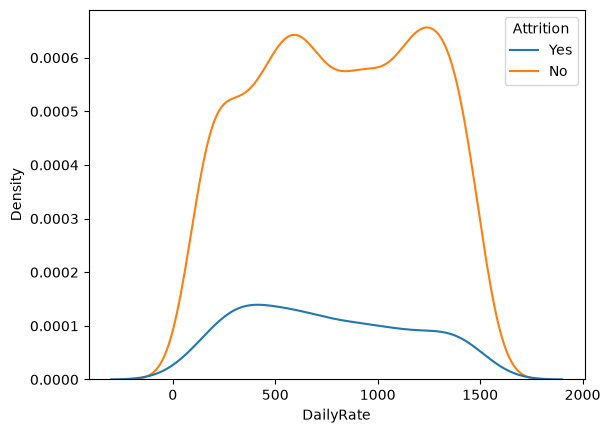

In [169]:
sns.kdeplot(df, x = "DailyRate", hue = "Attrition") # as rates increases - attrition decreases and most of the attrition happens between 0-1000 range 

<Axes: xlabel='RelationshipSatisfaction', ylabel='count'>

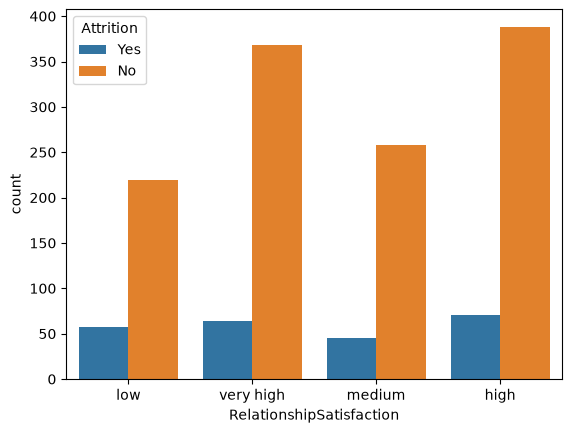

In [170]:
sns.countplot(df, x = "RelationshipSatisfaction", hue = "Attrition")

<Axes: xlabel='StockOptionLevel', ylabel='count'>

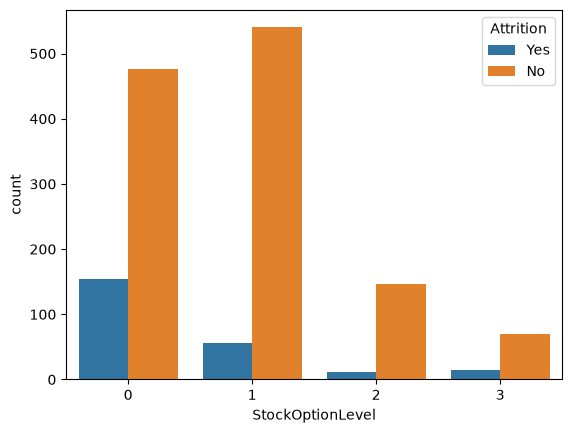

In [171]:
sns.countplot(df, x = "StockOptionLevel", hue = "Attrition") # people prefer having stocks and people with no stock options have more attrition rates

<Axes: xlabel='YearsSinceLastPromotion', ylabel='Density'>

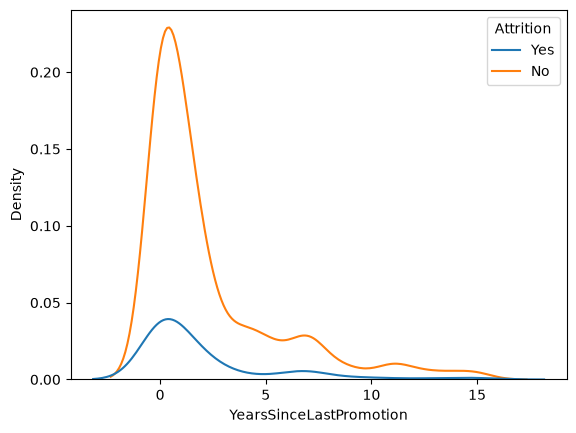

In [172]:
sns.kdeplot(df, x ="YearsSinceLastPromotion", hue = "Attrition") # more attrition amongst people with 0-3 years since last promotion

<Axes: xlabel='TrainingTimesLastYear', ylabel='Density'>

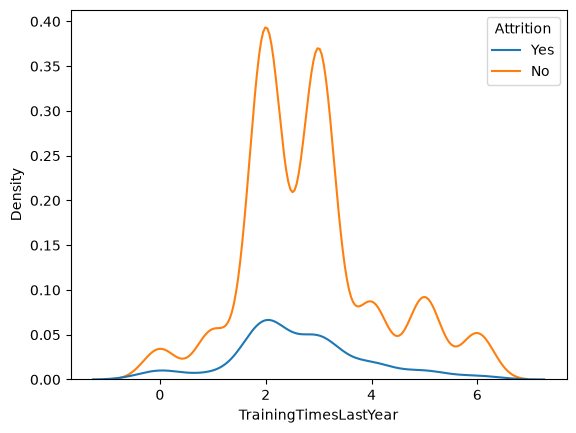

In [173]:
sns.kdeplot(df, x ="TrainingTimesLastYear", hue = "Attrition") # people who attend 2- 4 training sessions have more attrition

<Axes: xlabel='YearsInCurrentRole', ylabel='Density'>

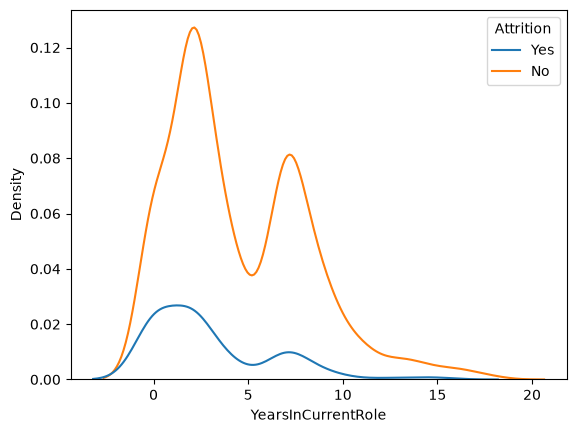

In [174]:
sns.kdeplot(df, x ="YearsInCurrentRole", hue = "Attrition") # people with 0-5 years of experience in current role are contributing more to the attrition rates

<Axes: xlabel='YearsWithCurrManager', ylabel='Density'>

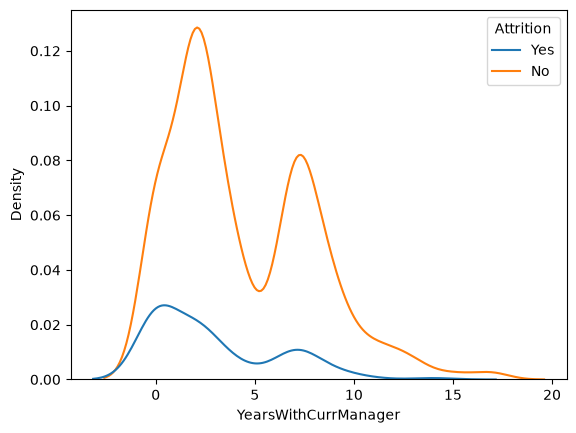

In [175]:
sns.kdeplot(df, x ="YearsWithCurrManager", hue = "Attrition") # similar to the previous graph

<Axes: xlabel='WorkLifeBalance', ylabel='count'>

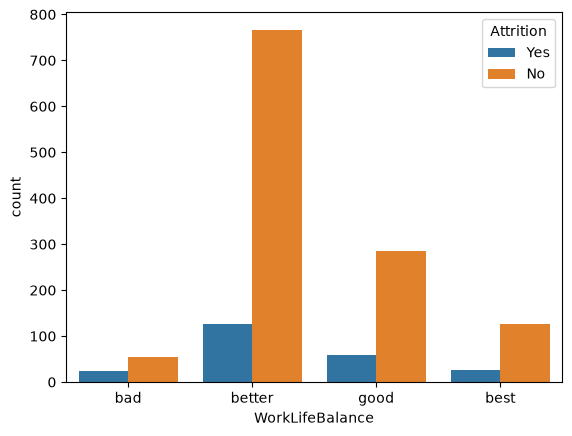

In [176]:
sns.countplot(df, x = "WorkLifeBalance", hue = "Attrition") # bad wlb - more attrition rates 

<Axes: xlabel='PercentSalaryHike', ylabel='Density'>

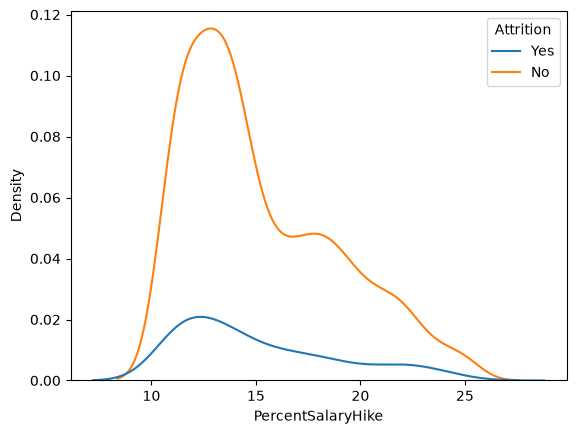

In [177]:
sns.kdeplot(df, x ="PercentSalaryHike", hue = "Attrition") # people with 10-20% salary hike are contributing more to the attrition rates

<Axes: xlabel='OverTime', ylabel='count'>

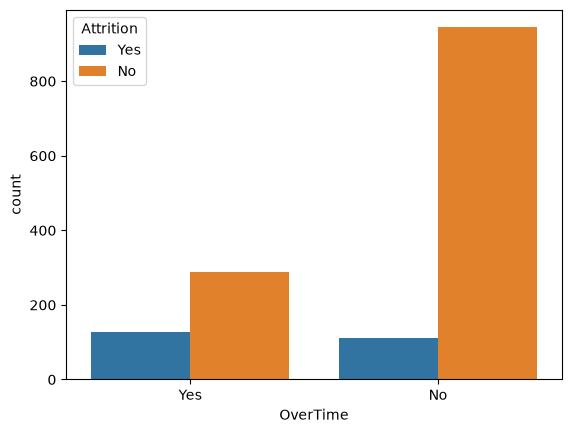

In [178]:
sns.countplot(df, x = "OverTime", hue = "Attrition") # people working in overtime leave the company in high numbers 

<Axes: xlabel='NumCompaniesWorked', ylabel='count'>

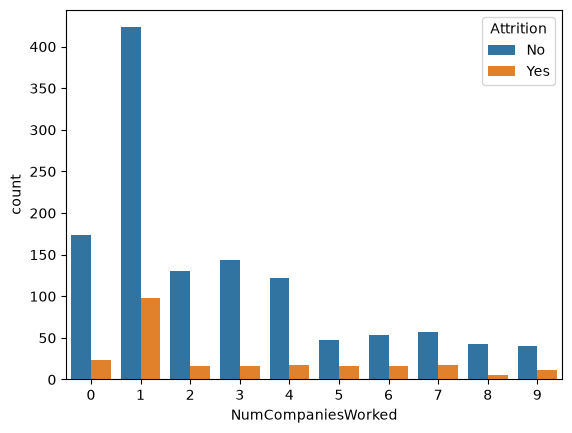

In [179]:
sns.countplot(df, x = "NumCompaniesWorked", hue = "Attrition") # people with lesser experience and people with 0-1 range is leaving the company more 

<Axes: xlabel='MonthlyRate', ylabel='Density'>

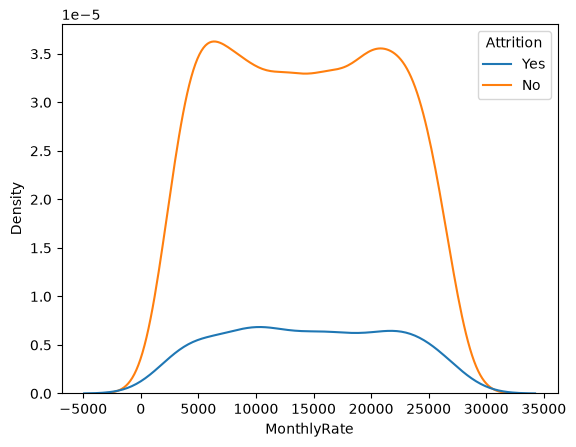

In [180]:
sns.kdeplot(df, x ="MonthlyRate", hue = "Attrition") # almost evenly split between 0- 30000

<Axes: xlabel='MonthlyIncome', ylabel='Density'>

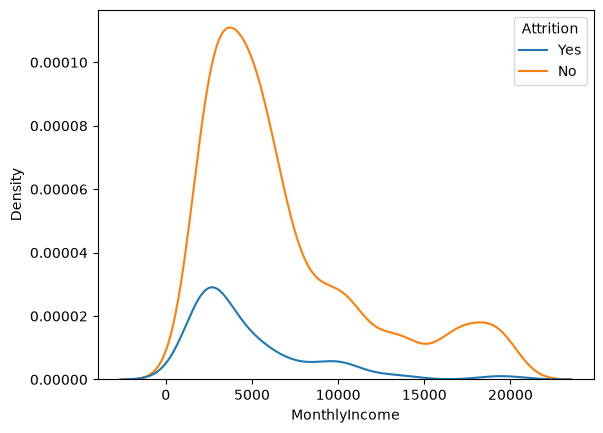

In [181]:
sns.kdeplot(df, x ="MonthlyIncome", hue = "Attrition") # people with lesser salary leave more (0-5000 range)

<Axes: xlabel='HourlyRate', ylabel='Density'>

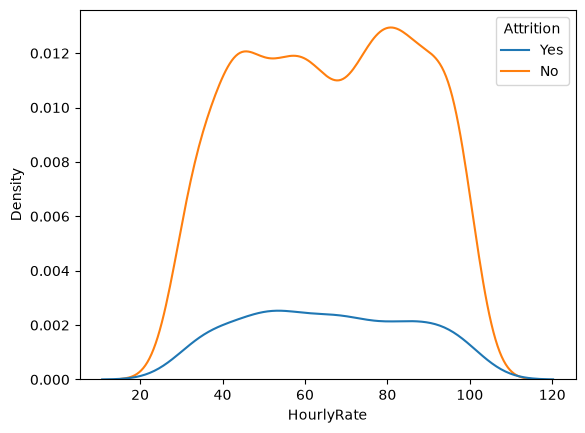

In [182]:
sns.kdeplot(df, x ="HourlyRate", hue = "Attrition") # almost a uniform distribution 

<Axes: xlabel='JobInvolvement', ylabel='count'>

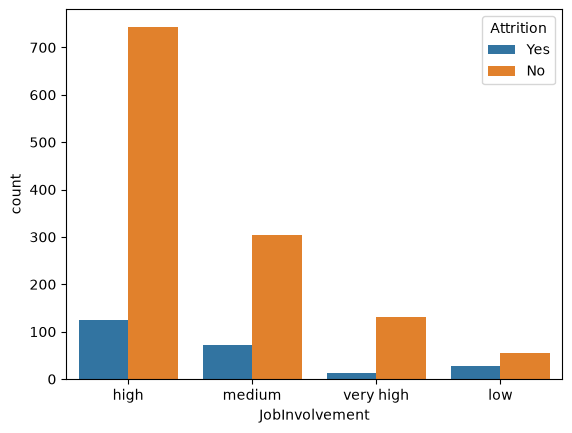

In [183]:
sns.countplot(df, x = "JobInvolvement", hue = "Attrition") # more involvement - more attrition 

<Axes: xlabel='JobLevel', ylabel='count'>

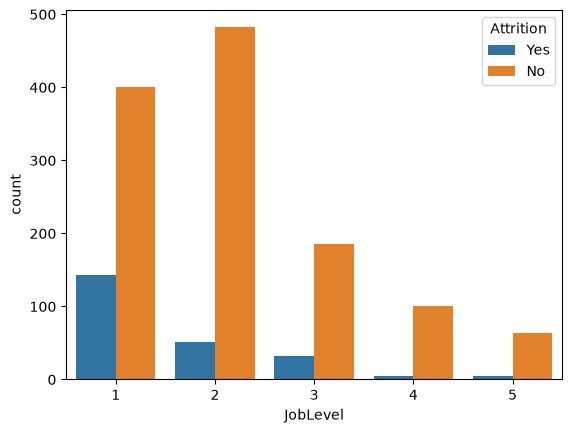

In [184]:
sns.countplot(df, x = "JobLevel", hue = "Attrition") # lower job level - more attrition 

<Axes: xlabel='count', ylabel='JobRole'>

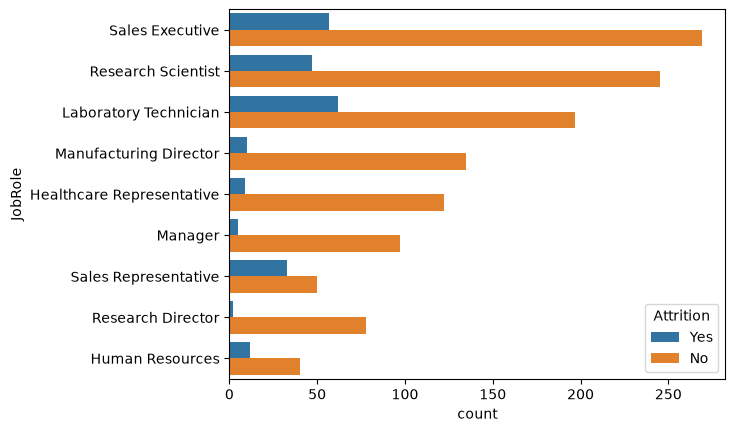

In [185]:
sns.countplot(df, y = "JobRole", hue = "Attrition") # more attrition in 4 categories - sales executive, research scientist, lab technician, sales representative

<Axes: xlabel='JobSatisfaction', ylabel='count'>

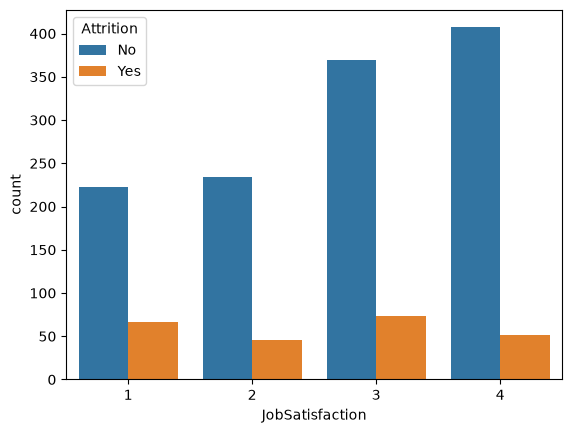

In [186]:
sns.countplot(df, x = "JobSatisfaction", hue = "Attrition") # lesser satisfication - more attrition

<Axes: xlabel='MaritalStatus', ylabel='count'>

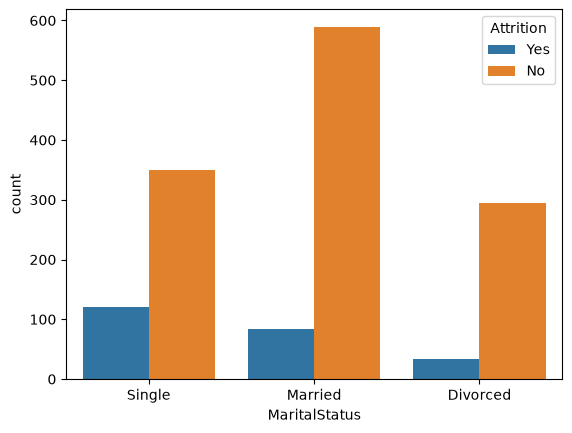

In [187]:
sns.countplot(df, x = "MaritalStatus", hue = "Attrition") # singles - more attrition